# Project 3 of 3: Supervised Machine Learning — Classification
**Studi Kasus:** Klasifikasi Status Kemiskinan Wilayah (`> 9,48%`) & Klaster Pembangunan IPM (`>= 75,0`) di Jawa Tengah (BPS 2025)

Kurikulum **Course 3 — Supervised Machine Learning: Classification**:
1. **Step 1 — Perumusan Target Biner & Pemisahan Fitur**
2. **Step 2 — Evaluasi 5 Algoritma Klasifikasi (*Logistic Regression, KNN, SVM, Decision Tree, Random Forest*)**
3. **Step 3 — Hyperparameter Tuning Nilai $k$ pada KNN**
4. **Step 4 — Visualisasi Dashboard 4-Panel Klasifikasi (*Confusion Matrix*, Kurva ROC, Tuning KNN, Feature Importance)**

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
np.random.seed(42)

def locate_dataset() -> str:
    cwd = os.getcwd()
    for p in [
        os.path.join(cwd, "bps_jawa_tengah_2025.csv"),
        os.path.join(cwd, "..", "bps_jawa_tengah_2025.csv"),
        os.path.join(cwd, "data", "bps_jawa_tengah_2025.csv"),
        "bps_jawa_tengah_2025.csv",
    ]:
        if os.path.exists(p):
            return p
    raise FileNotFoundError("Pastikan 'bps_jawa_tengah_2025.csv' ada di folder proyek.")

df = pd.read_csv(locate_dataset())
df["hls_rata_rata"] = (df["hls_laki_laki_2025"] + df["hls_perempuan_2025"]) / 2.0
df["uhh_rata_rata"] = (df["uhh_laki_laki_2025"] + df["uhh_perempuan_2025"]) / 2.0
df["gap_hls_gender"] = df["hls_perempuan_2025"] - df["hls_laki_laki_2025"]
df["log_pdrb"] = np.log(df["pdrb_adhb_2025_triliun_rp"])
df["is_kota"] = (df["tipe_wilayah"] == "Kota").astype(int)

df["status_kemiskinan_tinggi"] = (df["persentase_penduduk_miskin_2025"] > 9.48).astype(int)
df["klaster_ipm_maju"] = (df["ipm_2025"] >= 75.0).astype(int)

df[["nama_wilayah", "persentase_penduduk_miskin_2025", "status_kemiskinan_tinggi", "ipm_2025", "klaster_ipm_maju"]].head()

,nama_wilayah,persentase_penduduk_miskin_2025,status_kemiskinan_tinggi,ipm_2025,klaster_ipm_maju
0,Kabupaten Cilacap,9.41,0,73.45,0
1,Kabupaten Banyumas,11.15,1,75.44,1
2,Kabupaten Purbalingga,12.55,1,71.71,0
3,Kabupaten Banjarnegara,13.28,1,70.61,0
4,Kabupaten Kebumen,13.58,1,73.17,0


### Step 2 & 3: Evaluasi 5 Algoritma Klasifikasi via LOOCV & Hyperparameter Tuning KNN

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

X_pov = df[["ipm_2025", "hls_rata_rata", "uhh_rata_rata", "log_pdrb", "gap_hls_gender", "is_kota"]]
y_pov = df["status_kemiskinan_tinggi"]

X_ipm = df[["hls_rata_rata", "uhh_rata_rata", "persentase_penduduk_miskin_2025", "log_pdrb", "is_kota"]]
y_ipm = df["klaster_ipm_maju"]

X_pov_s = StandardScaler().fit_transform(X_pov)
X_ipm_s = StandardScaler().fit_transform(X_ipm)

models = [
    ("1. Logistic Regression (L2)", LogisticRegression(random_state=42), True),
    ("2. K-Nearest Neighbors (k=5)", KNeighborsClassifier(n_neighbors=5), True),
    ("3. Support Vector Machine (SVM)", SVC(kernel="linear", probability=True, random_state=42), True),
    ("4. Decision Tree (Gini)", DecisionTreeClassifier(max_depth=3, random_state=42), False),
    ("5. Random Forest Classifier", RandomForestClassifier(n_estimators=150, max_depth=4, random_state=42), False),
]

loo = LeaveOneOut()
clf_rows = []
roc_curves = []
best_cm = None

for name, clf, use_scale in models:
    Xp = X_pov_s if use_scale else X_pov
    Xi = X_ipm_s if use_scale else X_ipm
    pred_pov = cross_val_predict(clf, Xp, y_pov, cv=loo)
    prob_pov = cross_val_predict(clf, Xp, y_pov, cv=loo, method="predict_proba")[:, 1]
    if "Random Forest" in name:
        best_cm = confusion_matrix(y_pov, pred_pov)

    pred_ipm = cross_val_predict(clf, Xi, y_ipm, cv=loo)
    prob_ipm = cross_val_predict(clf, Xi, y_ipm, cv=loo, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_ipm, prob_ipm)
    auc_ipm = roc_auc_score(y_ipm, prob_ipm)
    roc_curves.append((name, fpr, tpr, auc_ipm))

    clf_rows.append({
        "Algoritma": name,
        "Acc Kemiskinan (%)": round(accuracy_score(y_pov, pred_pov)*100, 2),
        "F1 Kemiskinan (%)": round(f1_score(y_pov, pred_pov)*100, 2),
        "AUC Kemiskinan": round(roc_auc_score(y_pov, prob_pov), 4),
        "Acc Klaster IPM (%)": round(accuracy_score(y_ipm, pred_ipm)*100, 2),
        "AUC Klaster IPM": round(auc_ipm, 4),
    })

pd.DataFrame(clf_rows)

,Algoritma,Acc Kemiskinan (%),F1 Kemiskinan (%),AUC Kemiskinan,Acc Klaster IPM (%),AUC Klaster IPM
0,1. Logistic Regression (L2),65.71,64.71,0.7599,74.29,0.8791
1,2. K-Nearest Neighbors (k=5),60.00,61.11,0.6447,68.57,0.7990
2,3. Support Vector Machine (SVM),62.86,62.86,0.5888,77.14,0.8889
3,4. Decision Tree (Gini),68.57,66.67,0.6086,88.57,0.8758
4,5. Random Forest Classifier,71.43,70.59,0.7796,85.71,0.9412


### Step 4: Visualisasi Dashboard 4-Panel Klasifikasi

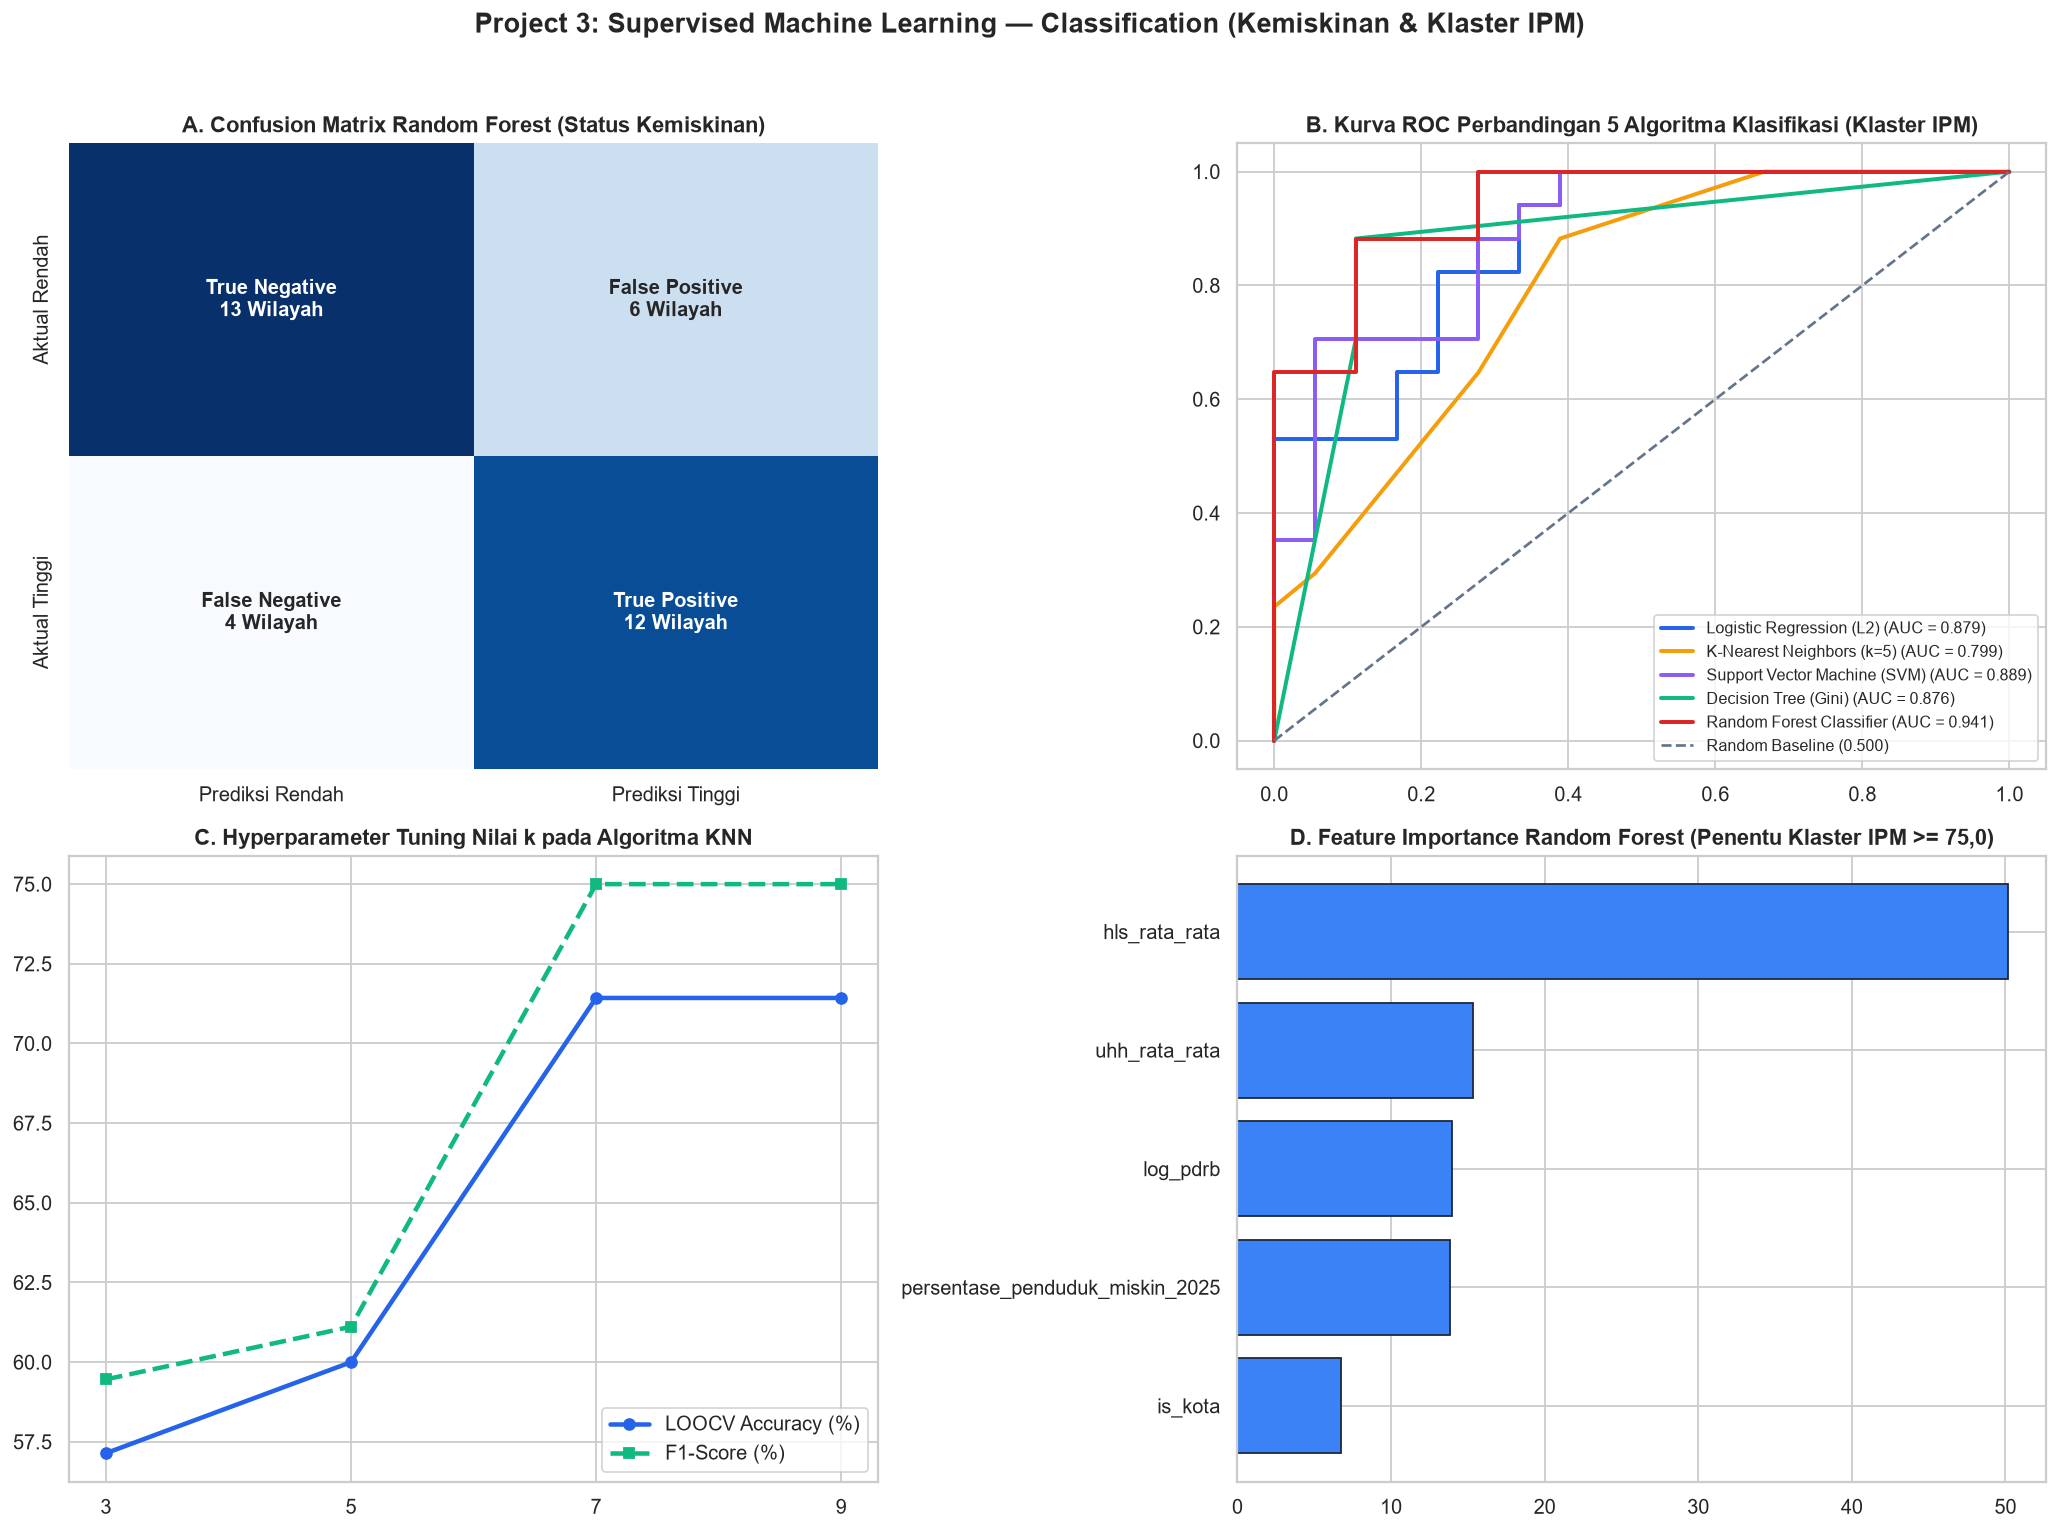

In [3]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=130)
fig.suptitle("Project 3: Supervised Machine Learning — Classification (Kemiskinan & Klaster IPM)", fontsize=15, fontweight="bold", y=0.98)

ax1 = axes[0, 0]
labels_cm = np.array([[f"True Negative\n{best_cm[0,0]} Wilayah", f"False Positive\n{best_cm[0,1]} Wilayah"], [f"False Negative\n{best_cm[1,0]} Wilayah", f"True Positive\n{best_cm[1,1]} Wilayah"]])
sns.heatmap(best_cm, annot=labels_cm, fmt="", cmap="Blues", cbar=False, xticklabels=["Prediksi Rendah", "Prediksi Tinggi"], yticklabels=["Aktual Rendah", "Aktual Tinggi"], annot_kws={"size": 11, "weight": "bold"}, ax=ax1)
ax1.set_title("A. Confusion Matrix Random Forest (Status Kemiskinan)", fontweight="bold")

ax2 = axes[0, 1]
for (name, fpr, tpr, auc_val), col in zip(roc_curves, ["#2563eb", "#f59e0b", "#8b5cf6", "#10b981", "#dc2626"]):
    ax2.plot(fpr, tpr, label=f"{name.split('. ')[1]} (AUC = {auc_val:.3f})", color=col, linewidth=2.2)
ax2.plot([0, 1], [0, 1], "--", color="#64748b", label="Random Baseline (0.500)")
ax2.set_title("B. Kurva ROC Perbandingan 5 Algoritma Klasifikasi (Klaster IPM)", fontweight="bold")
ax2.legend(loc="lower right", fontsize=9)

ax3 = axes[1, 0]
k_list = [3, 5, 7, 9]
acc_k = [accuracy_score(y_pov, cross_val_predict(KNeighborsClassifier(n_neighbors=k), X_pov_s, y_pov, cv=loo))*100 for k in k_list]
f1_k = [f1_score(y_pov, cross_val_predict(KNeighborsClassifier(n_neighbors=k), X_pov_s, y_pov, cv=loo))*100 for k in k_list]
ax3.plot(k_list, acc_k, marker="o", linewidth=2.5, color="#2563eb", label="LOOCV Accuracy (%)")
ax3.plot(k_list, f1_k, marker="s", linewidth=2.5, linestyle="--", color="#10b981", label="F1-Score (%)")
ax3.set_xticks(k_list)
ax3.set_title("C. Hyperparameter Tuning Nilai k pada Algoritma KNN", fontweight="bold")
ax3.legend(loc="lower right")

ax4 = axes[1, 1]
rf_fit = RandomForestClassifier(n_estimators=150, max_depth=4, random_state=42).fit(X_ipm, y_ipm)
imp_pairs = sorted(zip(X_ipm.columns, rf_fit.feature_importances_ * 100), key=lambda x: x[1])
ax4.barh([p[0] for p in imp_pairs], [p[1] for p in imp_pairs], color="#3b82f6", edgecolor="#1e293b")
ax4.set_title("D. Feature Importance Random Forest (Penentu Klaster IPM >= 75,0)", fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()